# Step 6: Pretrained reference, RoBERTa

**Reference only.** Pretrained models are not allowed in course results, so nothing here is part of the submission. Details: `docs/steps/06_pretrained_reference.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


best epoch 3.0, val AUC 0.8784, training 2.6 h


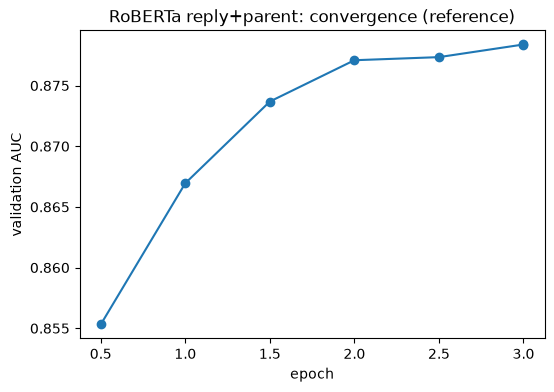

,epoch,val_auc
0,0.5,0.855313
1,1.0,0.866953
2,1.5,0.873683
3,2.0,0.877088
4,2.5,0.877343
5,3.0,0.878384
6,3.0,0.878380


In [2]:
# Convergence curve
j = U.read_json(U.EXP / "11_full_convergence/results/roberta_pair_conv__sarc_random.json")
e = pd.DataFrame(j["evals"]); print(f"best epoch {j['best_epoch']}, val AUC {j['val_auc']:.4f}, training {j['train_seconds']/3600:.1f} h")
fig, ax = plt.subplots(figsize=(6, 4)); ax.plot(e["epoch"], e["val_auc"], marker="o")
ax.set_xlabel("epoch"); ax.set_ylabel("validation AUC"); ax.set_title("RoBERTa reply+parent: convergence (reference)")
U.savefig(fig, "S06_roberta_curve.png"); plt.show(); e[["epoch", "val_auc"]]

In [3]:
# Test metrics
M = ["roberta_pair_conv", "roberta_pair_conv_s4248", "roberta_pair", "roberta_reply", "scratch_pair", "lgbm_lrscore_cues_contrast"]
test, val = U.predictions("sarc_random")
U.show(U.evaluate(test, val, M)[["label", "compliant", "roc_auc", "precision", "recall", "f1", "p75_recall"]])

,label,compliant,roc_auc,precision,recall,f1,p75_recall
0,"RoBERTa, reply + parent, converged",False,0.8809,0.7880,0.8216,0.8045,0.8640
1,"RoBERTa, converged, 2nd seed",False,0.8808,0.7900,0.8161,0.8029,0.8633
2,"RoBERTa, reply + parent, 1 epoch",False,0.8718,0.7846,0.8007,0.7926,0.8465
3,"RoBERTa, reply only, 1 epoch",False,0.8599,0.7839,0.7744,0.7792,0.8182
4,LightGBM + LR score + cues + contrast,True,0.8296,0.7746,0.7209,0.7468,0.7512
5,"From-scratch ESIM, reply + parent",True,0.8242,0.7485,0.7514,0.7499,0.7433


In [4]:
# Paired bootstrap
U.show(pd.concat([U.bootstrap_vs(test, ["roberta_pair"], ref="roberta_reply"),
                  U.bootstrap_vs(test, ["roberta_pair_conv"], ref="roberta_pair"),
                  U.bootstrap_vs(test, ["roberta_pair_conv"], ref="scratch_pair")]))

,model,vs,d_auc,ci_low,ci_high
0,roberta_pair,roberta_reply,0.0119,0.0112,0.0126
0,roberta_pair_conv,roberta_pair,0.0090,0.0082,0.0098
0,roberta_pair_conv,scratch_pair,0.0566,0.0550,0.0581


## 6.1 What the reference tells us

- Converged RoBERTa reaches **0.8809** (second seed 0.8808).
- Context with RoBERTa: reply+parent vs reply-only **+0.012** — the largest context gain of any model.
- Pretraining is worth roughly **+0.057** over the from-scratch ESIM that can also cross-attend reply and parent (part of this is Transformer vs BiLSTM architecture).
- It transfers best to Twitter-style data (FigLang Twitter 0.75, TweetEval 0.70); news headlines stay near 0.5 for every model.